# Model 6 — run 3: half the hidden layer

An independent copy of `model6.ipynb`. That notebook and its artifacts are never modified, and neither are `model2`'s.

**The one change is `hidden` 256 → 128.** Everything else is model 6's: the same data, split, seed, batch size, optimizer, learning rate, weight decay, Huber loss at beta 1.0, and early stopping.

**This run is about the engine, not about validation error.** `mlp` lost its fastchess match against plain material counting by 52 ± 37 Elo, and part of that is cost: at a fixed 200 ms the model searched 83,968 nodes to depth 4 where material — ten popcounts a side — searches further. Under the folding in CW-236 the first layer collapses into a table lookup whose cost is one vector add per occupied piece, so **the hidden width is the only thing that costs anything per node**:

| | parameters | ops/evaluation |
|---|---|---|
| `model6` 1 × 256 | 132,969 | 8,448 |
| this run 1 × 128 | **66,537** | **4,224** |

Half the arithmetic per position, which is depth bought back. The question is what it costs in accuracy — and whether that trade is favourable is a fastchess question, not an MSE one.

One thing to watch that is not about cost: at 66,537 parameters this has **7.5 training rows per parameter** against model 6's 3.8. Every run so far has overfit — train 0.194 against validation 0.246 — so a narrower model may lose less than the halving suggests, or even gain.

Artifacts: `model6_run7.pt`, `model6_run7_history.json`, `model6_run7_val_predictions.csv`.

Run top to bottom from a fresh kernel. `final_test.csv` is never opened here.

In [1]:
import csv, json, time
import sys
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn

# ml/ is the root whether the notebook is opened from ml/ or ml/notebooks/.
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "scripts"))

from canonical import MAX_CP
from encode import CATEGORIES, EMBED_DIM, FEATURES, INPUT_SIZE, SQUARES, encode
from targets import S, to_cp, to_target

DATA = ROOT / "data"
MODELS = ROOT / "models"
MODELS.mkdir(exist_ok=True)

# Every file this notebook writes is named from here, so a copy cannot half-rename
# itself and overwrite another run's checkpoint.
RUN = "model6_run7"
PARENT = "model6_run3"           # the run this one varies by exactly one value
BASELINE = "model2"         # the original, which every run is also measured against
BASELINE_PARAMETERS = 132_969

# One vector add per occupied square, plus the output dot — what CW-236's folded
# evaluator actually costs per position. Printed with the model so the engine
# consequence of a width change is visible at the point the width is chosen.
OCCUPIED = 32

torch.set_num_threads(4)
print(torch.__version__, "| inputs", INPUT_SIZE, "| run", RUN, "| parent", PARENT)

2.14.1+cpu | inputs 517 | run model6_run7 | parent model6_run3


## Experiment parameters

Model 6's values, with `hidden` halved. The loss stays Huber at beta 1.0 — that change was worth 5.6% on median centipawn error and is what makes this the engine's current model, so it is inherited rather than retested.

In [8]:
CONFIG = {
    "run": RUN,
    "parent": PARENT,
    # The full delta from model2: the inherited part first, this run's own change
    # after the plus.
    "changed_from_baseline": "Huber (SmoothL1, beta=1.0)  +  hidden 256 -> 128",
    "seed": 20261001,
    "embed_dim": EMBED_DIM,          # 8, from encode.py — not a second opinion
    "hidden": 64,                   # model6 is 256; this is the only change
    "batch_size": 1024,
    "lr": 1e-3,
    "weight_decay": 1e-4,
    "max_epochs": 60,
    "patience": 6,                   # epochs without improvement before stopping
    "optimizer": "AdamW",
    "loss": "SmoothL1 on asinh(cp / S)",
    "huber_beta": 1.0,               # the quadratic-to-linear crossover, in target units
    "S": S,
}
CONFIG

{'run': 'model6_run7',
 'parent': 'model6_run3',
 'changed_from_baseline': 'Huber (SmoothL1, beta=1.0)  +  hidden 256 -> 128',
 'seed': 20261001,
 'embed_dim': 8,
 'hidden': 64,
 'batch_size': 1024,
 'lr': 0.001,
 'weight_decay': 0.0001,
 'max_epochs': 60,
 'patience': 6,
 'optimizer': 'AdamW',
 'loss': 'SmoothL1 on asinh(cp / S)',
 'huber_beta': 1.0,
 'S': 1000}

## Dataset loading

Identical to the baseline, and deliberately so: if the data pipeline differed between runs, a difference in validation error would no longer be attributable to the one variable that changed.

In [9]:
def rows_of(split):
    """A split as (fen, target_value) pairs, in the file's own order.

    That order is (game_id, ply), inherited from the labeled file, so anything
    written back out alongside these rows lines up with the dataset.
    """
    with open(DATA / f"final_{split}.csv", newline="", encoding="utf-8") as fh:
        reader = csv.reader(fh)
        next(reader)                                   # fen,target_value
        return [(fen, int(target)) for fen, target in reader]


def load(rows):
    """Rows to tensors, encoded once up front.

    600,000 rows at 69 values is 41 MB as uint8, so the whole dataset lives in
    memory and every epoch after this is pure tensor arithmetic. Encoding inside
    the training loop would make a Python function call the bottleneck and hide
    what the model itself costs.

    Squares stay uint8 and are cast to long per batch: nn.Embedding needs int64
    indices, and holding 500,000 rows as int64 would be 256 MB for exactly the
    same information.
    """
    squares, flags, targets = [], [], []
    for fen, target in rows:
        position = encode(fen)
        squares.append(position.squares)
        flags.append((position.side_to_move,) + position.castling)
        # The one place centipawns become targets. Raw cp never enters a tensor,
        # so "loss is never computed on raw centipawns" holds by construction
        # rather than by remembering.
        targets.append(to_target(target))
    return (
        torch.from_numpy(np.array(squares, dtype=np.uint8)),
        torch.from_numpy(np.array(flags, dtype=np.float32)),
        torch.from_numpy(np.array(targets, dtype=np.float32)).unsqueeze(1),
    )


started = time.time()
train = load(rows_of("train"))       # the row list is not kept; only val's is
val_rows = rows_of("val")
val = load(val_rows)
# final_test.csv is deliberately not opened in this notebook. CW-164 froze it,
# and the simplest enforcement of that is its absence.
print(f"loaded and encoded in {time.time() - started:.0f}s")
print("train", tuple(train[0].shape), tuple(train[1].shape), tuple(train[2].shape))
print("val  ", tuple(val[0].shape), tuple(val[1].shape), tuple(val[2].shape))

loaded and encoded in 20s
train (500000, 64) (500000, 5) (500000, 1)
val   (50000, 64) (50000, 5) (50000, 1)


In [4]:
# Against the dataset's own measured numbers. A mate fraction far from 4.7% or a
# side-to-move split far from 49.8% would mean the encoder and the CSV disagree
# about what a row is — the one failure that would otherwise train quietly and
# evaluate nonsense.
squares, flags, targets = train
assert squares.shape[1] + flags.shape[1] == FEATURES == 69
assert 0 <= int(squares.min()) and int(squares.max()) < CATEGORIES
assert set(flags.unique().tolist()) <= {0.0, 1.0}

print(f"target  mean {targets.mean():+.4f}  std {targets.std():.4f}  "
      f"min {targets.min():+.4f}  max {targets.max():+.4f}")
median = float(targets.abs().median())
print(f"        median |target| {median:.4f}  ->  {to_cp(median):.0f} cp")
mates = (targets.abs() > to_target(MAX_CP)).float().mean()
print(f"mate band        {100 * mates:.1f}% of rows (expected 4.7%)")
print(f"White to move    {100 * flags[:, 0].mean():.1f}% (expected 49.8%)")

target  mean +0.0582  std 0.7998  min -3.0637  max +3.0637
        median |target| 0.2861  ->  290 cp
mate band        4.7% of rows (expected 4.7%)
White to move    49.8% (expected 49.8%)


## Model architecture

`517 → 128 → ReLU → 1`, against model 6's `517 → 256 → ReLU → 1`. The class, the construction order and the initialisation are unchanged — only the width differs.

The construction order is model 2's and must stay that way: every `nn.Linear` draws from the global RNG when it is constructed, so reordering those lines would change every initial weight and this would stop being one variable away from its parent.

In [10]:
class Model6(nn.Module):
    """Embedding(13, embed_dim) shared across all 64 squares, flattened and
    concatenated with the five binary inputs, through one hidden ReLU layer, to
    a single output.

    One hidden layer, deliberately. CW-236's folding turns the first layer into
    a precomputed table — one vector add per occupied square — so a single-layer
    model of any input width costs the same per position, while a second layer
    is a dense product that nothing can fold. That is why this family is the one
    the engine runs, and why width is the dial that matters here.

    The output carries no activation. Evaluations are signed, and the target
    spans roughly -3.06 to +3.06 after the asinh transform.
    """

    def __init__(self, categories=CATEGORIES, embed_dim=CONFIG["embed_dim"],
                 hidden=CONFIG["hidden"]):
        super().__init__()
        self.embed = nn.Embedding(categories, embed_dim)
        self.hidden = nn.Linear(SQUARES * embed_dim + 5, hidden)
        self.out = nn.Linear(hidden, 1)
        # Kaiming with the ReLU gain, which is what this layer actually feeds.
        # PyTorch's default assumes leaky_relu with a = sqrt(5) and leaves the
        # activations smaller than they should be.
        nn.init.kaiming_uniform_(self.hidden.weight, nonlinearity="relu")
        nn.init.zeros_(self.hidden.bias)

    def forward(self, squares, flags):
        x = self.embed(squares.long()).flatten(1)      # (B, 64, E) -> (B, 64E)
        x = torch.cat([x, flags], dim=1)               # (B, 64E + 5)
        return self.out(torch.relu(self.hidden(x)))


torch.manual_seed(CONFIG["seed"])
model = Model6()

# The encoder's layout and the layer's width have to agree, or CW-236's C++
# evaluator would be porting a different model than the one trained.
assert model.hidden.in_features == SQUARES * CONFIG["embed_dim"] + 5
parameters = sum(p.numel() for p in model.parameters())
CONFIG["parameters"] = parameters
print(model)
print(f"\n{parameters:,} parameters — "
      f"{100 * parameters / BASELINE_PARAMETERS:.0f}% of model6's "
      f"{BASELINE_PARAMETERS:,}")
print(f"{len(train[0]) / parameters:.1f} training rows each (model6 has 3.8)")
# What this costs the engine, which is the point of the run.
ops = OCCUPIED * CONFIG["hidden"] + CONFIG["hidden"]
print(f"{ops:,} operations per evaluation under the folding "
      f"(model6: {OCCUPIED * 256 + 256:,})")

Model6(
  (embed): Embedding(13, 8)
  (hidden): Linear(in_features=517, out_features=64, bias=True)
  (out): Linear(in_features=64, out_features=1, bias=True)
)

33,321 parameters — 25% of model6's 132,969
15.0 training rows each (model6 has 3.8)
2,112 operations per evaluation under the folding (model6: 8,448)


## Optimizer, loss, and the validation pass

**Two losses, with different jobs.** `criterion` is Huber: it is what the gradients come from and what the kept checkpoint is selected on, because a run must be selected on what it optimises. `mse` is computed over the same validation pass purely so this run stays comparable with the MSE-trained ones.

The real comparison is neither: median absolute error in centipawns is loss-independent, and that is what the later cells report.

In [11]:
optimizer = torch.optim.AdamW(model.parameters(), lr=CONFIG["lr"],
                              weight_decay=CONFIG["weight_decay"])
# Below an error of beta this is MSE/2 and above it absolute error, so the mate
# rows stop contributing in proportion to the square of a gap they will never
# close.
criterion = nn.SmoothL1Loss(beta=CONFIG["huber_beta"])
mse = nn.MSELoss()


@torch.no_grad()
def evaluate(data, chunk=8192):
    """Returns (training criterion, plain MSE) over a whole split.

    Both in one pass, so the cost is the same as reporting either alone.
    """
    model.eval()
    squares, flags, targets = data
    total_criterion = total_mse = 0.0
    for i in range(0, len(squares), chunk):
        predicted = model(squares[i:i + chunk], flags[i:i + chunk])
        actual = targets[i:i + chunk]
        total_criterion += criterion(predicted, actual).item() * len(predicted)
        total_mse += mse(predicted, actual).item() * len(predicted)
    return total_criterion / len(squares), total_mse / len(squares)


val_loss, val_mse = evaluate(val)
print(f"val huber at init  {val_loss:.4f}   (model6's was 0.2566)")
print(f"val MSE   at init  {val_mse:.4f}   (every run's is 0.7239)")
print(f"target variance    {val[2].var():.4f}")

val huber at init  0.2480   (model6's was 0.2566)
val MSE   at init  0.6992   (every run's is 0.7239)
target variance    0.6350


## Training loop

The baseline's, with plain MSE recorded beside the training criterion every epoch. Early stopping and the kept checkpoint follow the criterion being optimised.

For reference: `model6` reached **0.09869 Huber at epoch 9**, whose MSE was 0.25702. A narrower model usually trains to a slightly worse loss; whether it is worse *per node of search* is what fastchess decides.

In [12]:
CHECKPOINT = MODELS / f"{RUN}.pt"
HISTORY = MODELS / f"{RUN}_history.json"

generator = torch.Generator().manual_seed(CONFIG["seed"])
squares, flags, targets = train
n, batch = len(squares), CONFIG["batch_size"]

history, best, best_mse, best_epoch = [], float("inf"), None, 0
started = time.time()

for epoch in range(1, CONFIG["max_epochs"] + 1):
    model.train()
    # Seeded shuffle, so the run reproduces from the dataset files alone.
    order = torch.randperm(n, generator=generator)
    running = 0.0
    for i in range(0, n, batch):
        index = order[i:i + batch]
        optimizer.zero_grad()
        loss = criterion(model(squares[index], flags[index]), targets[index])
        loss.backward()
        optimizer.step()
        running += loss.item() * len(index)

    train_loss = running / n
    val_loss, val_mse = evaluate(val)
    history.append({"epoch": epoch, "train": train_loss,
                    "val": val_loss, "val_mse": val_mse})
    marker = ""

    # Selected on the criterion being optimised, not on the reported MSE.
    if val_loss < best:
        best, best_mse, best_epoch, marker = val_loss, val_mse, epoch, "  <- best"
        torch.save({"state_dict": model.state_dict(), "config": CONFIG,
                    "epoch": epoch, "val_loss": val_loss, "val_mse": val_mse},
                   CHECKPOINT)

    print(f"epoch {epoch:3}  train {train_loss:.5f}  val {val_loss:.5f}"
          f"  mse {val_mse:.5f}  {time.time() - started:5.0f}s{marker}")

    if epoch - best_epoch >= CONFIG["patience"]:
        print(f"\nstopping: no improvement in {CONFIG['patience']} epochs")
        break

HISTORY.write_text(json.dumps({"config": CONFIG, "best_epoch": best_epoch,
                               "best_val": best, "best_val_mse": best_mse,
                               "history": history}, indent=2))
print(f"\nbest huber {best:.5f} at epoch {best_epoch}  (its MSE {best_mse:.5f}) "
      f"— saved to {CHECKPOINT.name}")

epoch   1  train 0.22208  val 0.21642  mse 0.62859     10s  <- best
epoch   2  train 0.20306  val 0.17076  mse 0.48432     21s  <- best
epoch   3  train 0.13495  val 0.11722  mse 0.31182     30s  <- best
epoch   4  train 0.10996  val 0.10661  mse 0.27356     39s  <- best
epoch   5  train 0.10388  val 0.10196  mse 0.26326     49s  <- best
epoch   6  train 0.10035  val 0.09965  mse 0.25717     58s  <- best
epoch   7  train 0.09864  val 0.10042  mse 0.26107     67s
epoch   8  train 0.09760  val 0.09820  mse 0.25443     77s  <- best
epoch   9  train 0.09666  val 0.09797  mse 0.25510     88s  <- best
epoch  10  train 0.09609  val 0.09817  mse 0.25384     99s
epoch  11  train 0.09548  val 0.09884  mse 0.25581    110s
epoch  12  train 0.09496  val 0.09735  mse 0.25334    121s  <- best
epoch  13  train 0.09439  val 0.09754  mse 0.25451    133s
epoch  14  train 0.09368  val 0.09691  mse 0.25160    143s  <- best
epoch  15  train 0.09323  val 0.09759  mse 0.25408    157s
epoch  16  train 0.09276 

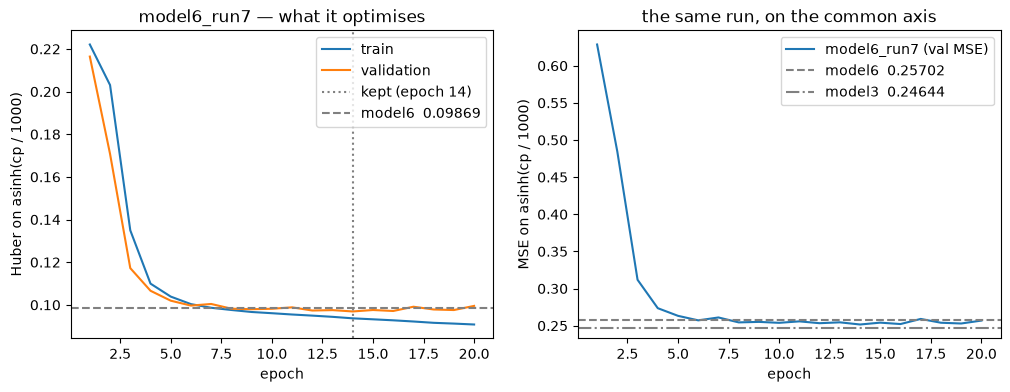

In [13]:
import matplotlib.pyplot as plt

epochs = [h["epoch"] for h in history]
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4))
left.plot(epochs, [h["train"] for h in history], label="train")
left.plot(epochs, [h["val"] for h in history], label="validation")
left.axvline(best_epoch, color="grey", linestyle=":",
             label=f"kept (epoch {best_epoch})")
left.axhline(0.09869, color="grey", linestyle="--", label="model6  0.09869")
left.set(xlabel="epoch", ylabel="Huber on asinh(cp / 1000)",
         title=f"{RUN} — what it optimises")
left.legend()

right.plot(epochs, [h["val_mse"] for h in history], label=f"{RUN} (val MSE)")
right.axhline(0.25702, color="grey", linestyle="--", label="model6  0.25702")
right.axhline(0.24644, color="grey", linestyle="-.", label="model3  0.24644")
right.set(xlabel="epoch", ylabel="MSE on asinh(cp / 1000)",
          title="the same run, on the common axis")
right.legend()
plt.show()

## Validation error in centipawns

Loss-independent, so this compares across every run without an asterisk — and it is the number the engine consumes.

| | median | mean | sign |
|---|---|---|---|
| `model2` (MSE) | 173.9 cp | 618.1 cp | 23.2% |
| `model3` (2 × 187) | 169.0 cp | 603.0 cp | 22.1% |
| `model6` (Huber, 256) | **164.2 cp** | 602.0 cp | 21.7% |

A model that costs half as much per node can afford to be somewhat worse here. How much worse is affordable is a fastchess question — but a median past about 200 cp would be hard to argue for at any speed.

In [14]:
model.load_state_dict(torch.load(CHECKPOINT, weights_only=True)["state_dict"])
model.eval()
with torch.no_grad():
    predicted = torch.cat([model(val[0][i:i + 8192], val[1][i:i + 8192])
                           for i in range(0, len(val[0]), 8192)])

predicted_cp = S * torch.sinh(predicted.squeeze(1))
actual_cp = S * torch.sinh(val[2].squeeze(1))
error = (predicted_cp - actual_cp).abs()

print(f"median absolute error  {error.median():8.1f} cp   (model6 164.2)")
print(f"mean   absolute error  {error.mean():8.1f} cp   (model6 602.0)")
disagree = ((predicted_cp > 0) != (actual_cp > 0)).float().mean()
print(f"sign disagreement      {100 * disagree:8.1f}%   (model6 21.7)")

median absolute error     160.3 cp   (model6 164.2)
mean   absolute error     594.8 cp   (model6 602.0)
sign disagreement          21.0%   (model6 21.7)


In [15]:
# Bucketed by the magnitude of the true evaluation. The 0-300 band is where games
# are decided and where classification.js's thresholds live.
#
#                              model2                    model6 (Huber, 256)
#   mate rows        2,347     median 8389.4 sign  6.6%  median 8740.7 sign 7.7%
#   cp rows only    47,653     median  161.2 sign 24.0%  median  152.3 sign 22.3%
#   |actual| < 100  16,637     median   74.5 sign 41.5%  median   73.1 sign 38.9%
#   100 - 300        9,064     median  126.8 sign 26.1%  median  118.2 sign 24.6%
#   300 - 1000      20,016     median  299.8 sign 10.6%  median  279.8 sign  9.5%
#   above 1000       1,936     median  619.8 sign  2.2%  median  527.0 sign  2.1%
is_mate = actual_cp.abs() > MAX_CP


def report(label, mask):
    if not mask.any():
        return
    chosen = error[mask]
    wrong = ((predicted_cp[mask] > 0) != (actual_cp[mask] > 0)).float().mean()
    print(f"{label:16} n {int(mask.sum()):6,} ({100 * mask.float().mean():4.1f}%)  "
          f"median {chosen.median():7.1f}  mean {chosen.mean():8.1f}  "
          f"sign {100 * wrong:5.1f}%")


report("mate rows", is_mate)
report("cp rows only", ~is_mate)
print()
for low, high, label in [(0, 100, "|actual| < 100"), (100, 300, "100 - 300"),
                         (300, 1000, "300 - 1000"), (1000, 10 ** 9, "above 1000")]:
    report(label, ~is_mate & (actual_cp.abs() >= low) & (actual_cp.abs() < high))

share = error[is_mate].sum() / error.sum()
print(f"\nthe mate rows carry {100 * share:.0f}% of the total absolute error "
      f"(model2 58%, model6 61%)")

mate rows        n  2,347 ( 4.7%)  median  8537.6  mean   7537.3  sign   7.1%
cp rows only     n 47,653 (95.3%)  median   148.5  mean    252.8  sign  21.6%

|actual| < 100   n 16,637 (33.3%)  median    63.5  mean    109.5  sign  38.2%
100 - 300        n  9,064 (18.1%)  median   115.6  mean    151.3  sign  23.0%
300 - 1000       n 20,016 (40.0%)  median   278.9  mean    355.2  sign   9.1%
above 1000       n  1,936 ( 3.9%)  median   543.5  mean    901.1  sign   2.0%

the mate rows carry 59% of the total absolute error (model2 58%, model6 61%)


## Real against predicted, one row per validation position

`actual_cp` is the dataset's `target_value`, taken from the CSV as the integer it is rather than round-tripped through the transform, so the comparison carries none of our own arithmetic. For the 4.7% of rows that are mates, that value is the mate-band encoding (10,010 to 10,680) rather than a centipawn score the engine reported — hence `is_mate`, which is the column to filter on before reading any average.

In [16]:
PREDICTIONS = MODELS / f"{RUN}_val_predictions.csv"

# load() preserved the order it was given and the predictions were built by
# walking the tensors in order, so row i of each is the same position. The
# assert is here because a silent misalignment would look like a badly trained
# model rather than like a bug.
assert len(val_rows) == len(predicted_cp)

with open(PREDICTIONS, "w", newline="", encoding="utf-8") as fh:
    writer = csv.writer(fh)
    writer.writerow(("fen", "actual_cp", "predicted_cp", "error_cp", "is_mate"))
    for (fen, actual), prediction in zip(val_rows, predicted_cp.tolist()):
        writer.writerow((fen, actual, round(prediction, 1),
                         round(prediction - actual, 1),
                         int(abs(actual) > MAX_CP)))

print(f"{len(val_rows):,} rows -> {PREDICTIONS}  "
      f"({PREDICTIONS.stat().st_size / 1e6:.1f} MB)")
print(f"\nto put this model in the engine:")
print(f"  python scripts/export_weights.py {RUN}")
print(f"  copy models/{RUN}.weights into engine/cpp/build/")
print(f"  setoption name EvalFile value {RUN}.weights")

50,000 rows -> c:\Users\Uziel\Desktop\Projects\Chess Project\ml\models\model6_run7_val_predictions.csv  (3.9 MB)

to put this model in the engine:
  python scripts/export_weights.py model6_run7
  copy models/model6_run7.weights into engine/cpp/build/
  setoption name EvalFile value model6_run7.weights


## Every run so far

Reads the history files, not the notebooks, so no other run is touched or re-run. Two deltas per row: against `model2`, and against each run's own parent.

The `ops` column is what the engine pays per position under CW-236's folding — one vector add per occupied square through the first layer, then every later layer dense. It is the column that decides what can actually be shipped, and it is why a model winning on validation MSE is not automatically the one to export.

run                val MSE    params       ops   vs model2   loss    changed
model5             0.23598   133,077         0    -0.02232   MSE     MLP -> 2-layer CNN over 8x8 planes (parameter-matched)
model7             0.24511   132,799    19,849    -0.01318   MSE     one-hot input + two hidden layers of 136
model8             0.24585   132,351    44,535    -0.01245   MSE     one hidden layer of 256 -> three of 158
model3             0.24644   132,314    41,140    -0.01185   MSE     one hidden layer of 256 -> two of 187
model3_run2        0.24783   149,225    24,640    -0.01046   MSE     two hidden layers of 187  +  (nothing yet)
model6_run7        0.25160    33,321     2,112    -0.00670   Huber   Huber (SmoothL1, beta=1.0)  +  hidden 256 -> 128
model6_run3        0.25499    66,537     4,224    -0.00330   Huber   Huber (SmoothL1, beta=1.0)  +  hidden 256 -> 128
model4             0.25563   214,785     8,448    -0.00266   MSE     Embedding(13, 8) -> one-hot (13 per square)
model2_run2 

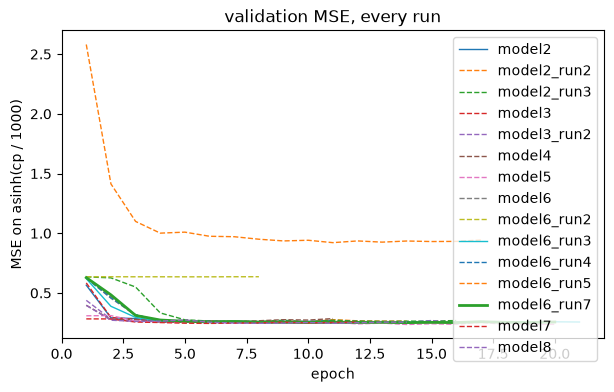

In [17]:
runs = {path.name.replace("_history.json", ""): json.loads(path.read_text())
        for path in sorted(MODELS.glob("*_history.json"))}


def common(entry):
    """Validation MSE, whatever the run was trained on. Older histories predate
    the extra column, and for those best_val IS the MSE."""
    return entry.get("best_val_mse", entry["best_val"])


def cost(config):
    """Operations per evaluation in the engine, under the folding."""
    widths = config.get("hidden")
    if not isinstance(widths, list):
        widths = [widths]
    if any(w is None for w in widths) or config.get("channels"):
        return 0                      # a convolutional model folds differently
    total = OCCUPIED * widths[0]
    for first, second in zip(widths, widths[1:]):
        total += first * second
    return total + widths[-1]


base = common(runs[BASELINE])
print(f"{'run':16} {'val MSE':>9}  {'params':>8}  {'ops':>8}  "
      f"{'vs model2':>10}   {'loss':<7} changed")
for name, entry in sorted(runs.items(), key=lambda kv: common(kv[1])):
    config = entry["config"]
    loss = "Huber" if "SmoothL1" in config.get("loss", "") else "MSE"
    print(f"{name:16} {common(entry):9.5f}  {config.get('parameters', 0):8,}  "
          f"{cost(config):8,}  {common(entry) - base:+10.5f}   {loss:<7} "
          f"{config.get('changed_from_baseline') or '—'}")

fig, ax = plt.subplots(figsize=(7, 4))
for name, entry in runs.items():
    ax.plot([h["epoch"] for h in entry["history"]],
            [h.get("val_mse", h["val"]) for h in entry["history"]],
            label=name, linewidth=2 if name == RUN else 1,
            linestyle="-" if name in (RUN, PARENT, BASELINE) else "--")
ax.set(xlabel="epoch", ylabel="MSE on asinh(cp / 1000)",
       title="validation MSE, every run")
ax.legend()
plt.show()